# Project 2 - Persuasive / Deceptive Visualization
**Proposition:** "The world is winning the fight against climate change."
Dataset: World Bank Human Development Indicators (CO2 + GDP), 1990-2018.

Run top to bottom. It builds the data, draws 4 charts + a writeup page, and saves `checkpoint_charts.pdf`.

**Before running:** set `DATA_DIR` below to the folder where you unzipped the
`World-Bank-Data-by-Indicators` repo (the folder that contains `climate-change/`, `economy-and-growth/`, etc.).

In [1]:
import pandas as pd, numpy as np, glob, textwrap
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.ticker import FuncFormatter, MaxNLocator

# ---> set this to your downloaded World Bank data folder <---
DATA_DIR = "."

P = "average_value_"  # the cleaned CSVs prefix every indicator column with this

In [2]:
import os
print("Jupyter is running in:", os.getcwd())
print("What's here:", os.listdir("."))
print("DATA_DIR is:", DATA_DIR)

Jupyter is running in: /Users/KittyNinja/Documents/World-Bank-Data-by-Indicators-master
What's here: ['social-development', '.DS_Store', 'social-protection-and-labor', 'Project2_climate_viz.ipynb', 'trade', 'poverty', 'health', 'engergy-and-mining', 'education', 'aid-effectiveness', 'gender', 'public-sector', 'checkpoint_charts.pdf', 'financial-sector', 'economy-and-growth', 'agriculture-and-rural-development', 'README.md', 'climate-change', 'science-and-technology', 'recipe.wrangle', 'environment', '.ipynb_checkpoints', 'external-debt', 'urban-development', 'infrastructure', 'private-sector']
DATA_DIR is: .


## 1. Load the raw columns we need and keep real countries only

In [3]:
def col(folder, name, short):
    f = f"{DATA_DIR}/{folder}/{folder}.csv"
    d = pd.read_csv(f, usecols=["Country Code", "Year", P + name])
    d.columns = ["Country Code", "Year", short]
    return d

co2kt  = col("climate-change", "CO2 emissions (kt)", "co2kt")
co2pc  = col("climate-change", "CO2 emissions (metric tons per capita)", "co2pc")
gdppc  = col("economy-and-growth", "GDP per capita (constant 2010 US$)", "gdppc")
pop    = col("health", "Population, total", "pop")

# metadata: Region is filled only for real countries (blank for World/regions/income aggregates)
meta = pd.read_csv(glob.glob(f"{DATA_DIR}/health/Metadata_Country*")[0])
countries = meta[meta.Region.notna()][["Country Code", "IncomeGroup"]]
print("Real countries:", len(countries))

d = (co2kt.merge(co2pc, how="outer").merge(gdppc, how="outer")
          .merge(pop, how="outer").merge(countries))   # inner merge drops aggregate rows
d.head()

Real countries: 217


,Country Code,Year,co2kt,co2pc,gdppc,pop,IncomeGroup
0,ABW,1960,11092.675,204.631696,NaN,54208.0,High income
1,ABW,1961,11576.719,208.837879,NaN,55434.0,High income
2,ABW,1962,12713.489,226.081890,NaN,56234.0,High income
3,ABW,1963,12178.107,214.785217,NaN,56699.0,High income
4,ABW,1964,11840.743,207.626699,NaN,57029.0,High income


## 2. Build the global series each chart needs

In [4]:
def popw(s, c):  # population-weighted global average of a per-country value
    s = s.dropna(subset=[c, "pop"]); return (s[c] * s["pop"]).sum() / s["pop"].sum()

def global_intensity(yr):  # correct global carbon intensity = total CO2 / total GDP
    s = d[d.Year == yr].dropna(subset=["co2kt", "gdppc", "pop"])
    return s.co2kt.sum() * 1e6 / (s.gdppc * s["pop"]).sum()

yrs = list(range(1990, 2019))
g = pd.DataFrame({
    "totGt":  [d[d.Year == y].co2kt.sum() / 1e6 for y in yrs],   # total emissions, gigatons
    "pc":     [popw(d[d.Year == y], "co2pc") for y in yrs],       # CO2 per person
    "gdppc":  [popw(d[d.Year == y], "gdppc") for y in yrs],       # GDP per person
    "intenG": [global_intensity(y) for y in yrs],                 # carbon intensity
}, index=yrs)

# per-person CO2 by income group (for the page-2 chart)
ig = d.groupby(["Year", "IncomeGroup"]).apply(lambda s: popw(s, "co2pc")).unstack()
g.loc[[1990, 2018]].round(2)

/var/folders/rc/b3_533b572vcjcr484mhtm9w0000gp/T/ipykernel_11718/2745585030.py:2: RuntimeWarning: invalid value encountered in scalar divide
  s = s.dropna(subset=[c, "pop"]); return (s[c] * s["pop"]).sum() / s["pop"].sum()
/var/folders/rc/b3_533b572vcjcr484mhtm9w0000gp/T/ipykernel_11718/2745585030.py:2: RuntimeWarning: invalid value encountered in scalar divide
  s = s.dropna(subset=[c, "pop"]); return (s[c] * s["pop"]).sum() / s["pop"].sum()
/var/folders/rc/b3_533b572vcjcr484mhtm9w0000gp/T/ipykernel_11718/2745585030.py:2: RuntimeWarning: invalid value encountered in scalar divide
  s = s.dropna(subset=[c, "pop"]); return (s[c] * s["pop"]).sum() / s["pop"].sum()
/var/folders/rc/b3_533b572vcjcr484mhtm9w0000gp/T/ipykernel_11718/2745585030.py:2: RuntimeWarning: invalid value encountered in scalar divide
  s = s.dropna(subset=[c, "pop"]); return (s[c] * s["pop"]).sum() / s["pop"].sum()
/var/folders/rc/b3_533b572vcjcr484mhtm9w0000gp/T/ipykernel_11718/2745585030.py:2: RuntimeWarning: invali

,totGt,pc,gdppc,intenG
1990,20.32,3.88,7111.63,0.53
2018,33.58,4.45,10960.32,0.41


## 3. Shared styling

In [5]:
INK, MUTED, GRID = "#1f2933", "#6b7785", "#e6e9ed"
TEAL, RED, BLUE = "#1b7f79", "#c0452b", "#27597a"
SRC = ("Source: World Bank World Development Indicators (CO2 and GDP), 1990-2018. "
       "Global figures are population weighted,\nwhile totals sum all reporting countries.")
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False,
                     "axes.spines.right": False, "text.parse_math": False})  # $ renders literally

def head(ax, title, sub):
    ax.set_title("\n".join(textwrap.wrap(title, 60)), loc="left",
                 fontsize=12.5, fontweight="bold", color=INK, pad=34)
    ax.text(0, 1.02, sub, transform=ax.transAxes, fontsize=8.5, color=MUTED, va="bottom")

def style(ax):
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, labelsize=8.5, length=0)
    for s in ("left", "bottom"): ax.spines[s].set_color("#c9ced4")

def new_page(note):
    fig = plt.figure(figsize=(8.5, 11))
    fig.text(0.07, 0.965, note, fontsize=8, color=MUTED)
    a1 = fig.add_axes([0.11, 0.575, 0.82, 0.275])
    a2 = fig.add_axes([0.11, 0.10, 0.82, 0.275])
    fig.text(0.07, 0.035, SRC, fontsize=7.3, color=MUTED)
    return fig, a1, a2

pdf = PdfPages("checkpoint_charts.pdf")

## 4. Page 1 - arguing the proposition is TRUE (we're winning)
Chart 1: carbon intensity falling. Chart 2: economy vs. emissions-per-person, indexed.

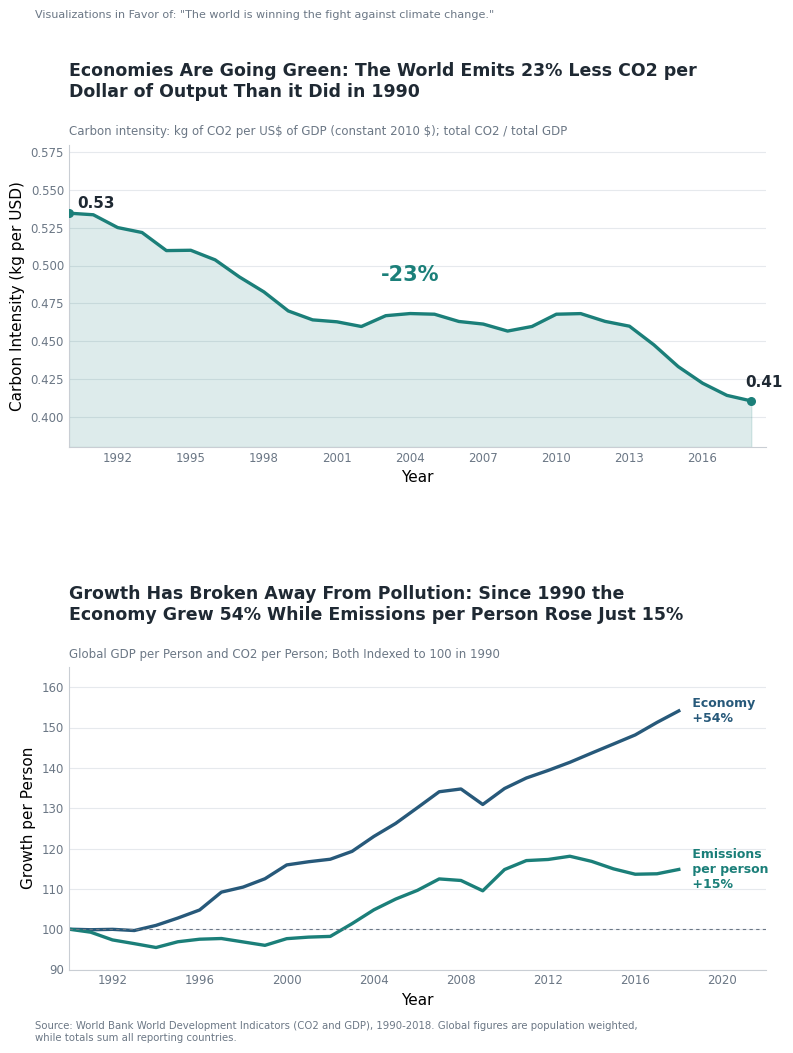

In [6]:
fig, a1, a2 = new_page('Visualizations in Favor of: "The world is winning the fight against climate change."')

# Chart 1: carbon intensity (truncated axis = deceptive)
ci = g.intenG
a1.fill_between(ci.index, 0.38, ci.values, color=TEAL, alpha=0.15)
a1.plot(ci.index, ci.values, color=TEAL, lw=2.4)
a1.set_ylim(0.38, 0.58); a1.set_xlim(1990, 2018.6)
a1.scatter([1990, 2018], [ci[1990], ci[2018]], color=TEAL, s=30, zorder=3)
a1.annotate(f"{ci[1990]:.2f}", (1990, ci[1990]), xytext=(6, 4), textcoords="offset points", fontsize=11, fontweight="bold", color=INK)
a1.annotate(f"{ci[2018]:.2f}", (2018, ci[2018]), xytext=(-4, 10), textcoords="offset points", fontsize=11, fontweight="bold", color=INK)
a1.text(2004, 0.49, f"-{(1-ci[2018]/ci[1990])*100:.0f}%", fontsize=15, fontweight="bold", color=TEAL, ha="center")
a1.set_xlabel("Year", fontsize = 11)
a1.set_ylabel("Carbon Intensity (kg per USD)", fontsize = 11)
head(a1, "Economies Are Going Green: The World Emits 23% Less CO2 per Dollar of Output Than it Did in 1990",
     "Carbon intensity: kg of CO2 per US$ of GDP (constant 2010 $); total CO2 / total GDP")
style(a1)

# Chart 2: decoupling, indexed to 1990 = 100
gi = g.gdppc / g.gdppc[1990] * 100
cpi = g.pc / g.pc[1990] * 100
a2.plot(gi.index, gi.values, color=BLUE, lw=2.4)
a2.plot(cpi.index, cpi.values, color=TEAL, lw=2.4)
a2.set_ylim(90, 165); a2.set_xlim(1990, 2022)
a2.text(2018.4, gi[2018], f" Economy\n +{gi[2018]-100:.0f}%", color=BLUE, fontsize=9, fontweight="bold", va="center")
a2.text(2018.4, cpi[2018], f" Emissions\n per person\n +{cpi[2018]-100:.0f}%", color=TEAL, fontsize=9, fontweight="bold", va="center")
a2.axhline(100, color=MUTED, lw=0.8, ls=(0, (3, 3)))
a2.set_xlabel("Year", fontsize = 11)
a2.set_ylabel("Growth per Person", fontsize = 11)
head(a2, "Growth Has Broken Away From Pollution: Since 1990 the Economy Grew 54% While Emissions per Person Rose Just 15%",
     "Global GDP per Person and CO2 per Person; Both Indexed to 100 in 1990")
style(a2)

#plt.savefig('page1.pdf', dpi = 500)
pdf.savefig(fig); plt.show()

## 5. Page 2 - arguing the proposition is FALSE (we're losing)
Chart 1: total emissions rising. Chart 2: per-person emissions in the developing world.

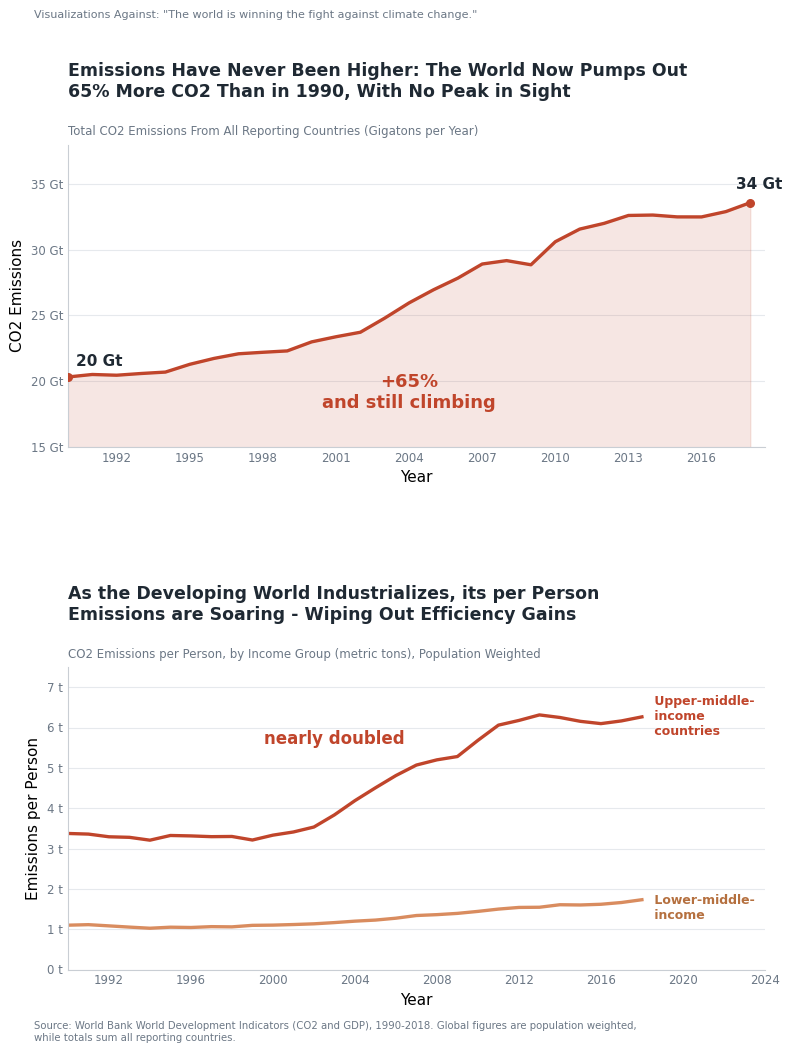

In [7]:
fig, a1, a2 = new_page('Visualizations Against: "The world is winning the fight against climate change."')

# Chart 1: total emissions (honest, zero baseline)
tt = g.totGt
a1.fill_between(tt.index, 0, tt.values, color=RED, alpha=0.13)
a1.plot(tt.index, tt.values, color=RED, lw=2.4)
a1.set_ylim(15, 38); a1.set_xlim(1990, 2018.6)
a1.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f} Gt"))
a1.scatter([1990, 2018], [tt[1990], tt[2018]], color=RED, s=30, zorder=3)
a1.annotate(f"{tt[1990]:.0f} Gt", (1990, tt[1990]), xytext=(6, 8), textcoords="offset points", fontsize=11, fontweight="bold", color=INK)
a1.annotate(f"{tt[2018]:.0f} Gt", (2018, tt[2018]), xytext=(-10, 10), textcoords="offset points", fontsize=11, fontweight="bold", color=INK)
a1.text(2004, 18, f"+{(tt[2018]/tt[1990]-1)*100:.0f}%\nand still climbing", fontsize=13, fontweight="bold", color=RED, ha="center")
a1.set_xlabel("Year", fontsize = 11)
a1.set_ylabel("CO2 Emissions", fontsize = 11)
head(a1, "Emissions Have Never Been Higher: The World Now Pumps Out 65% More CO2 Than in 1990, With No Peak in Sight",
     "Total CO2 Emissions From All Reporting Countries (Gigatons per Year)")
style(a1)

# Chart 2: per-person emissions, developing world (drops high-income = deceptive)
um = ig["Upper middle income"].loc[1990:2018]
lm = ig["Lower middle income"].loc[1990:2018]
a2.plot(um.index, um.values, color=RED, lw=2.4)
a2.plot(lm.index, lm.values, color="#d98c5f", lw=2.4)
a2.set_ylim(0, 7.5); a2.set_xlim(1990, 2024)
a2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f} t"))
a2.text(2018.4, um[2018], " Upper-middle-\n income\n countries", color=RED, fontsize=9, fontweight="bold", va="center")
a2.text(2018.4, lm[2018]-0.2, " Lower-middle-\n income", color="#b5703f", fontsize=9, fontweight="bold", va="center")
a2.text(2003, 5.6, "nearly doubled", fontsize=12, fontweight="bold", color=RED, ha="center")
a2.set_xlabel("Year", fontsize = 11)
a2.set_ylabel("Emissions per Person", fontsize = 11)
head(a2, "As the Developing World Industrializes, its per Person Emissions are Soaring - Wiping Out Efficiency Gains",
     "CO2 Emissions per Person, by Income Group (metric tons), Population Weighted")
style(a2)

#plt.savefig('page2.pdf', dpi = 500)
pdf.savefig(fig); plt.show()